# Diseño, implementación y validación experimental de una torreta autónoma basada en aprendizaje por refuerzo profundo y visión artificial (CV) (2 de 3)
- Este es el **segundo** de 3 notebooks donde aplico transfer learning y fine-tunning de la CNN YoloV8 para la identificación y extraccion de las coordenadas de una diana de disparo para la torreta.
- Los otros dos notebooks se pueden encontrar en la entrega o los enlaces a Kaggle:

1. [parte1-rl-gymnasium](https://www.kaggle.com/code/jorgesu040/parte1-rl-gymnasium)
3. [parte3-aplicacion-rl-cv-en-el-mundo-real](https://www.kaggle.com/code/jorgesu040/parte3-aplicacion-rl-cv-en-el-mundo-real)

Versión para GitHub de la entrega final. Las figuras corresponden al experimento original.
Consulta el [README](../README.md) para preparar el dataset y reproducir la evaluación.

# 1. Introducción
Este notebook constituye la segunda pieza del proyecto de montar una Torreta Autónoma. Mientras que el agente de Reinforcement Learning actúa como el "cerebro motor" que decide cómo mover los servos, este sistema actúa como los "ojos" de la torreta.

Aunque en clase hemos estudiado las Redes Neuronales Convolucionales (CNNs) para clasificación de imágenes y como hacerlas y que se pueden usar para detectar objetos, no hemos visto cómo implementarlas. El problema de controlar una torreta requiere Detección de Objetos (Object Detection): saber qué hay y dónde está (coordenadas X, Y).

He investigado por mi cuenta cómo implementar esto utilizando la arquitectura YOLO (You Only Look Once), concebida originalmente por Joseph Redmon por su capacidad de procesar imágenes en una sola pasada. Para esta implementación práctica, he utilizado la versión YOLOv8, mantenida y por Ultralytics y su libreria que facilita muchísimo la creación.

- Bajo el capó, YOLOv8 utiliza PyTorch, el que vimos para NLP en clase. La red procesa la imagen completa en un único paso (feed-forward) para predecir simultáneamente las clases y las coordenadas de las cajas (bounding boxes).

In [ ]:
import os
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

dataset_dir = Path(os.environ.get("SHOOTING_TARGET_DIR", PROJECT_ROOT / "data" / "shooting-target"))
dataset_yaml = dataset_dir / "data.yaml"
run_dir = PROJECT_ROOT / "runs" / "detect"

In [ ]:
import os
import numpy as np 
import pandas as pd 

# 2. Selección de Arquitectura y Librería
Para la deteccion de dianas he usado la libreria de los creadores de YOLO `ultralitics`, y he usado este tutorial sobre como usarla  [Object Detection using yolov8](https://www.geeksforgeeks.org/machine-learning/object-detection-using-yolov8/). 
Y me he basado en la documentación de `ultralitics` [Ultralytics YOLO Docs - Python Usage](https://docs.ultralytics.com/usage/python/#train)

- La idea es usar la arquitecta de YOLO, una red neuronal convolucional (CNN) que tiene arquitectura está diseñada como un detector de una etapa.
- Así pues, he decidido usar la librería de `ultralitics` y un modelo de YOLOv8 preentrenado, con un dataset de dianas subido en roboflow, para aplicar Transfer learning.

Incialmente iba a aplicar Keras-CV pero la curva de aprendizaje era mayor para el tiempo disponible. Ultralytics ofrece una API en Python mucho más sencilla y potente para realizar Transfer Learning rápidamente.

El link al dataset de las imagenes: [Shooting Target Object Detection](https://universe.roboflow.com/final-project-lmkzv/shooting-target)

> **Nota**: por temas de cómputo/comodidad, el proyecto lo he ejecutado en kaggle donde he subido el dataset de dianas que he descargado

## Transfer Learning y Fine-Tuning

Aplicando los conceptos de clase, he utilizado Transfer Learning para aprovechar el conocimiento previo de la red:

1. Modelo Pre-entrenado: partimos de los pesos de yolov8n.pt (Nano), pre-entrenado con COCO.
2. Fine-Tuning: la librería de Ultralytics simplifica el proceso al congelar automáticamente las capas base durante el inicio del entrenamiento, permitiendo ajustar los pesos finales a mi caso de uso específico.

## Dataset
He utilizado un dataset específico de dianas de tiro alojado en Roboflow:

- Fuente: Shooting Target Object Detection (Roboflow)
- El dataset ya viene etiquetado y dividido en conjuntos de Train, Validation y Test ademas de en formato para que pueda ser utilizado por ultralytics, lo que facilita la evaluación del modelo.

### Evaluar los pesos publicados

Con el dataset preparado, puedes ejecutar esta celda para evaluar el checkpoint incluido en CPU. Continúa con las celdas siguientes si quieres repetir el entrenamiento.

In [ ]:
from ultralytics import YOLO

checkpoint = PROJECT_ROOT / "models" / "best.pt"
saved_detector = YOLO(str(checkpoint))
saved_metrics = saved_detector.val(
    data=str(dataset_yaml), split="test", device="cpu", imgsz=640, batch=4,
    workers=0, plots=False, project=str(run_dir), name="published-checkpoint",
)
print(f"mAP@0.50: {saved_metrics.box.map50:.4f}")
print(f"mAP@0.50–0.95: {saved_metrics.box.map:.4f}")

In [ ]:
import torch
from ultralytics import YOLO

# 1. Cargar el modelo Nano
model = YOLO('yolov8n.pt')

# 2. Entrenar
model.train(
    data=str(dataset_yaml),
    project=str(run_dir),
    name="train",
    exist_ok=True, 
    epochs=20, 
    imgsz=640, 
    batch=-1 if torch.cuda.is_available() else 4,  # AutoBatch en GPU
    verbose=False,
    patience=10,
)
                

In [ ]:
import os
import glob
from IPython.display import Image, display

entrenamiento_dir = model.trainer.save_dir

# 3. Resultados y Análisis

- Una ventaja significativa de utilizar la librería Ultralytics es su capacidad para calcular automáticamente el rendimiento y generar visualizaciones detalladas al finalizar el entrenamiento. Esto ha facilitado enormemente el análisis de errores sin necesidad de programar callbacks de monitoreo complejos manualmente.

 Para evaluar el rendimiento del modelo, lo medimos generalmente con la métrica mAP@50 (mean Average Precision) en lugar de la precisión simple (Accuracy), ya que en detección de objetos no solo se necesita verificar no solo la clase correcta, sino también la localización exacta. El mAP@50 calcula la precisión media considerando una detección como válida solo si su caja predicha se solapa al menos un 50% (Intersection over Union > 0.5) con la caja real, lo cual es el estándar para asegurar que la torreta realmente está "viendo" el objetivo en su posición física correcta.

## Análisis de Métricas (Curvas de entrenamiento) y gráficas de Entrenamiento (History)
Analizando las gráficas de resultados obtenidas durante las 20 épocas de entrenamiento:
- Las curvas de pérdida (train/box_loss, train/cls_loss) muestran un descenso pronunciado y constante, estabilizándose hacia la época 15, lo que indica un aprendizaje efectivo sin signos graves de overfitting.
- La métrica (Mean Average Precision al 50% de IoU) alcanza valores cercanos al 0.99 al final del entrenamiento. Esto confirma que el modelo no solo clasifica bien, sino que las cajas predichas se ajustan muy bien a los objetos reales.

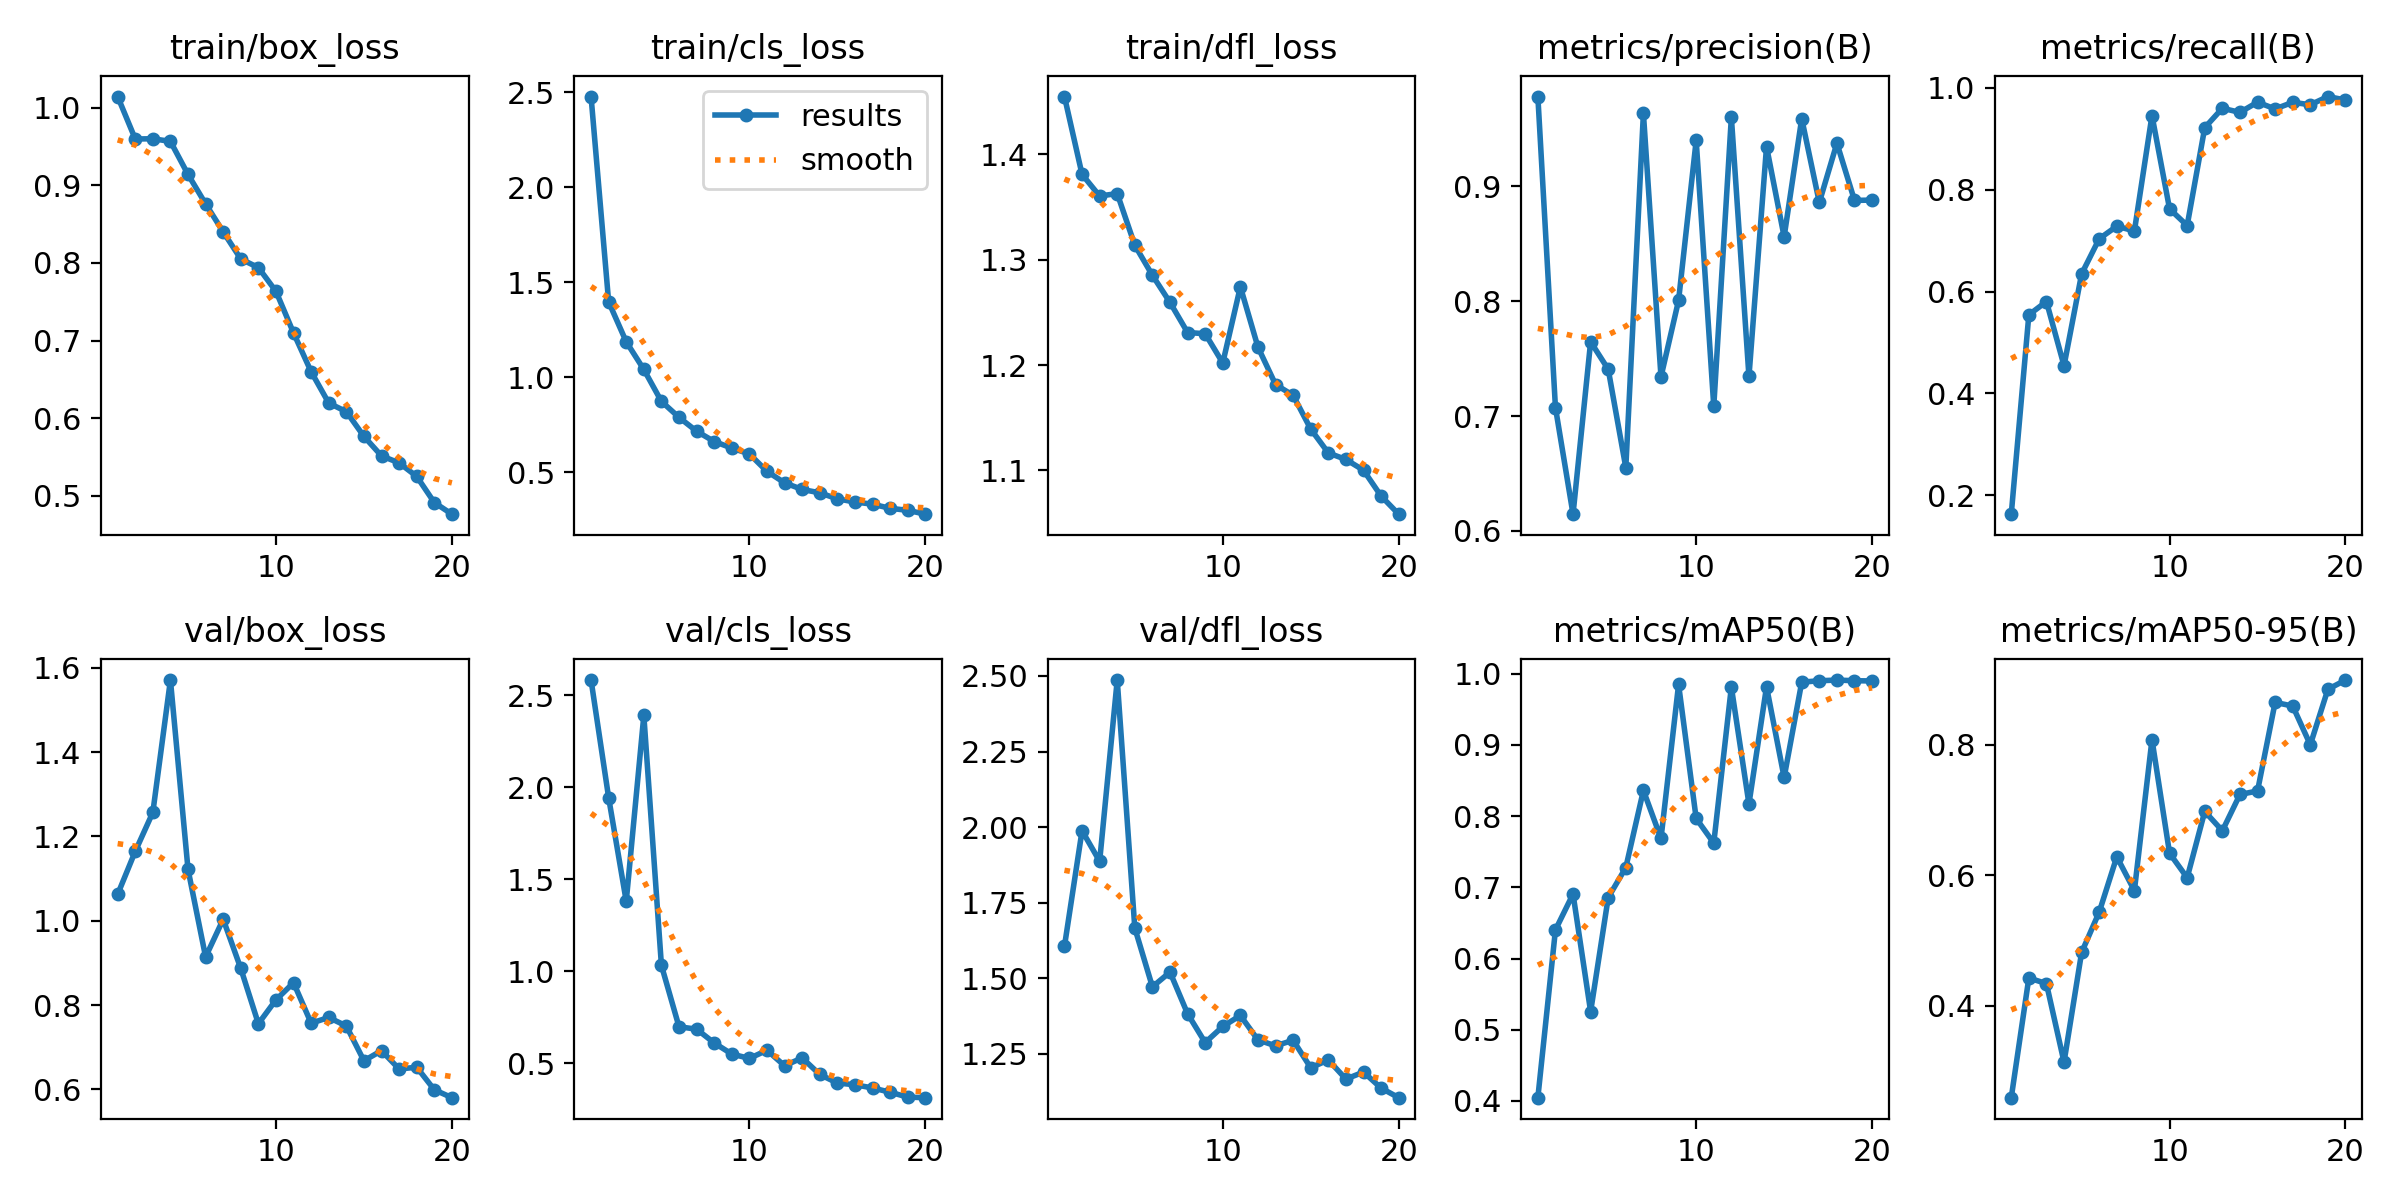

In [5]:
# Mostramos la gráfica 'results.png' que YOLO genera automáticamente
# Muestra la evolución del Loss y las métricas de validación durante el entrenamiento.
print("--- Gráficas de Entrenamiento (Loss, Precision, Recall, mAP) ---")
display(Image(filename=os.path.join(entrenamiento_dir, 'results.png')))

## Análisis de Errores (Matriz de Confusión)
La matriz de confusión muestra que el modelo funciona muy bien:

- La diana redonda es la que mejor reconoce, con 153 aciertos y casi ningún fallo.
- A veces confunde la diana de pecho con la cuadrada porque se parecen, pero pasa muy poco.
- Fondo: Casi nunca confunde las paredes con dianas, así que la torreta no disparará a lo loco.

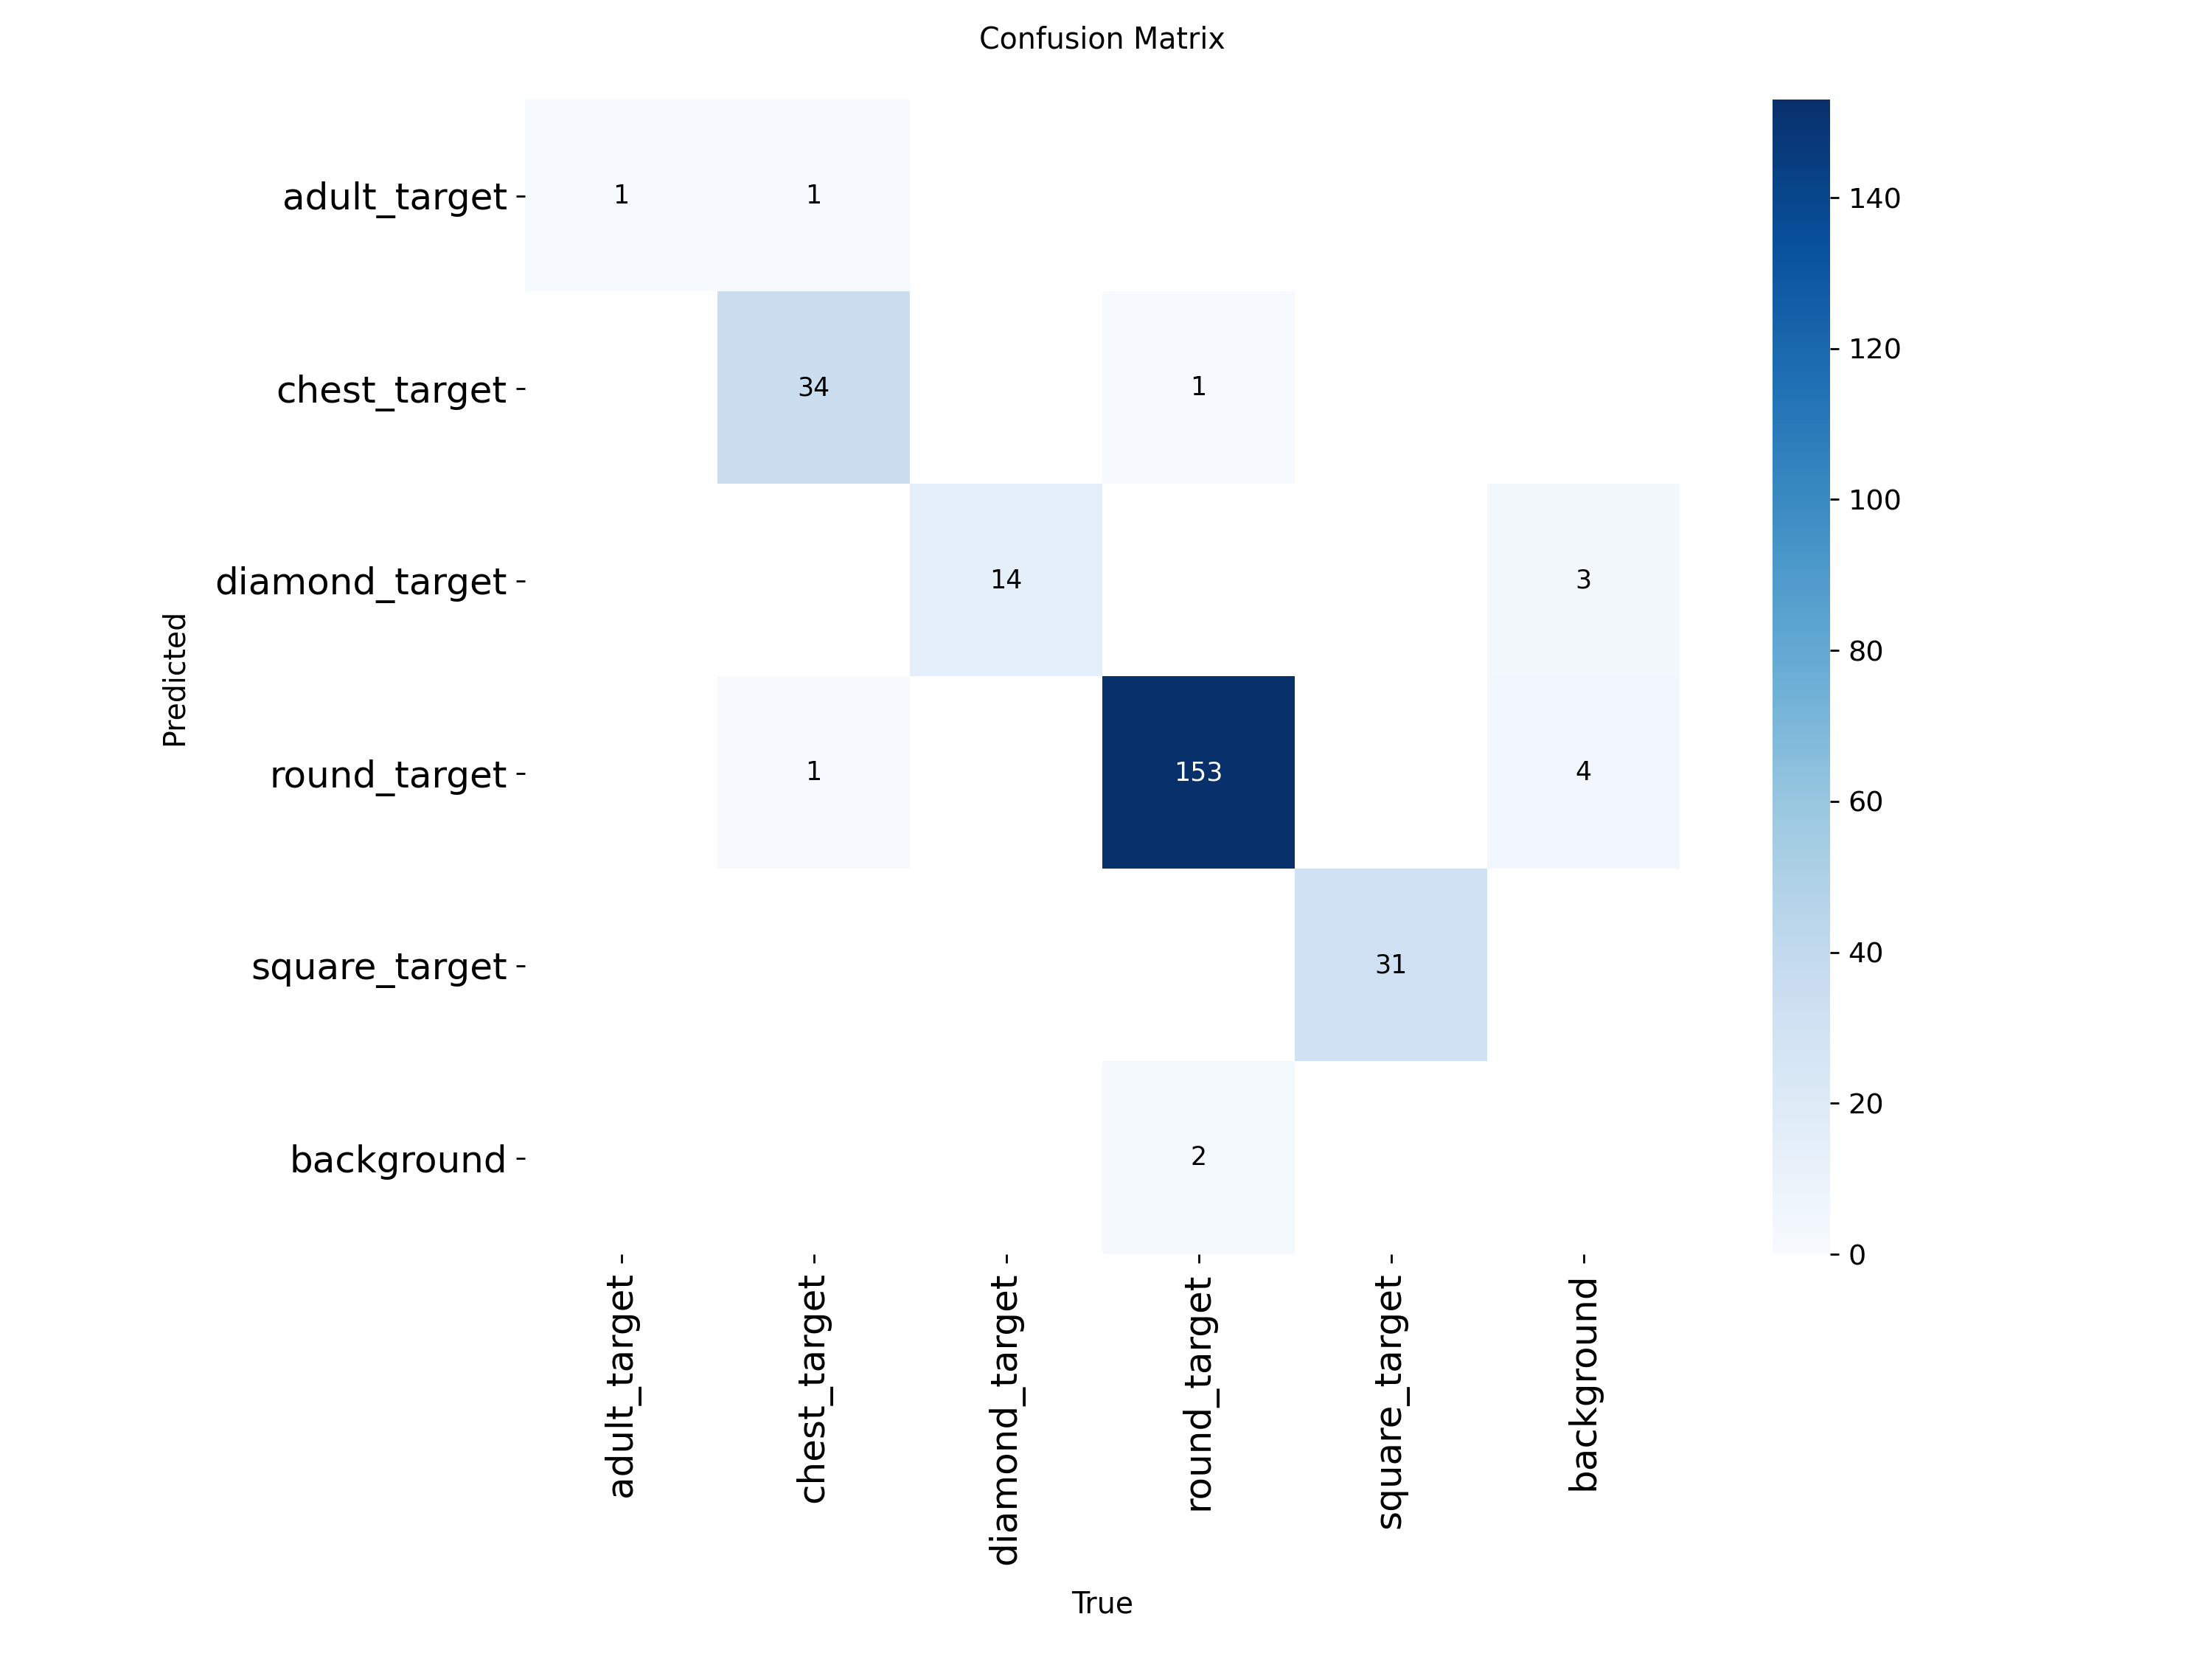

In [6]:
# Mostramos la matriz de confusión guardada en la carpeta de entrenamiento
print("--- Matriz de Confusión (Validación) ---")
display(Image(filename=os.path.join(entrenamiento_dir, 'confusion_matrix.png')))

## Ejecución de Test y Visualización


- Por defecto, ultralitics gurada los mejores pesos (best.pt) que obtuvieron las mejores métricas durante el entrenamiento, ignorando las últimas épocas si estas empeoraron.
- Aplicando (model.val) se ejecuta la inferencia sobre el dataset de test y calcula las métricas de rendimiento reales.
- Viendo las gráficas, el modelo ha salido casi perfecto. La curva de Precisión-Recall (PR Curve) nos da un valor de 0.989, lo que básicamente significa que no se le escapa casi ninguna diana y cuando dice que ve una, es verdad.

- Si miramos la Matriz de Confusión, la diagonal azul oscuro confirma que acierta casi siempre, sobre todo con las dianas redondas. Solo se lía un poco (muy poco) distinguiendo entre la diana cuadrada y la de pecho, lo cual es normal porque se parecen mucho geométricamente.


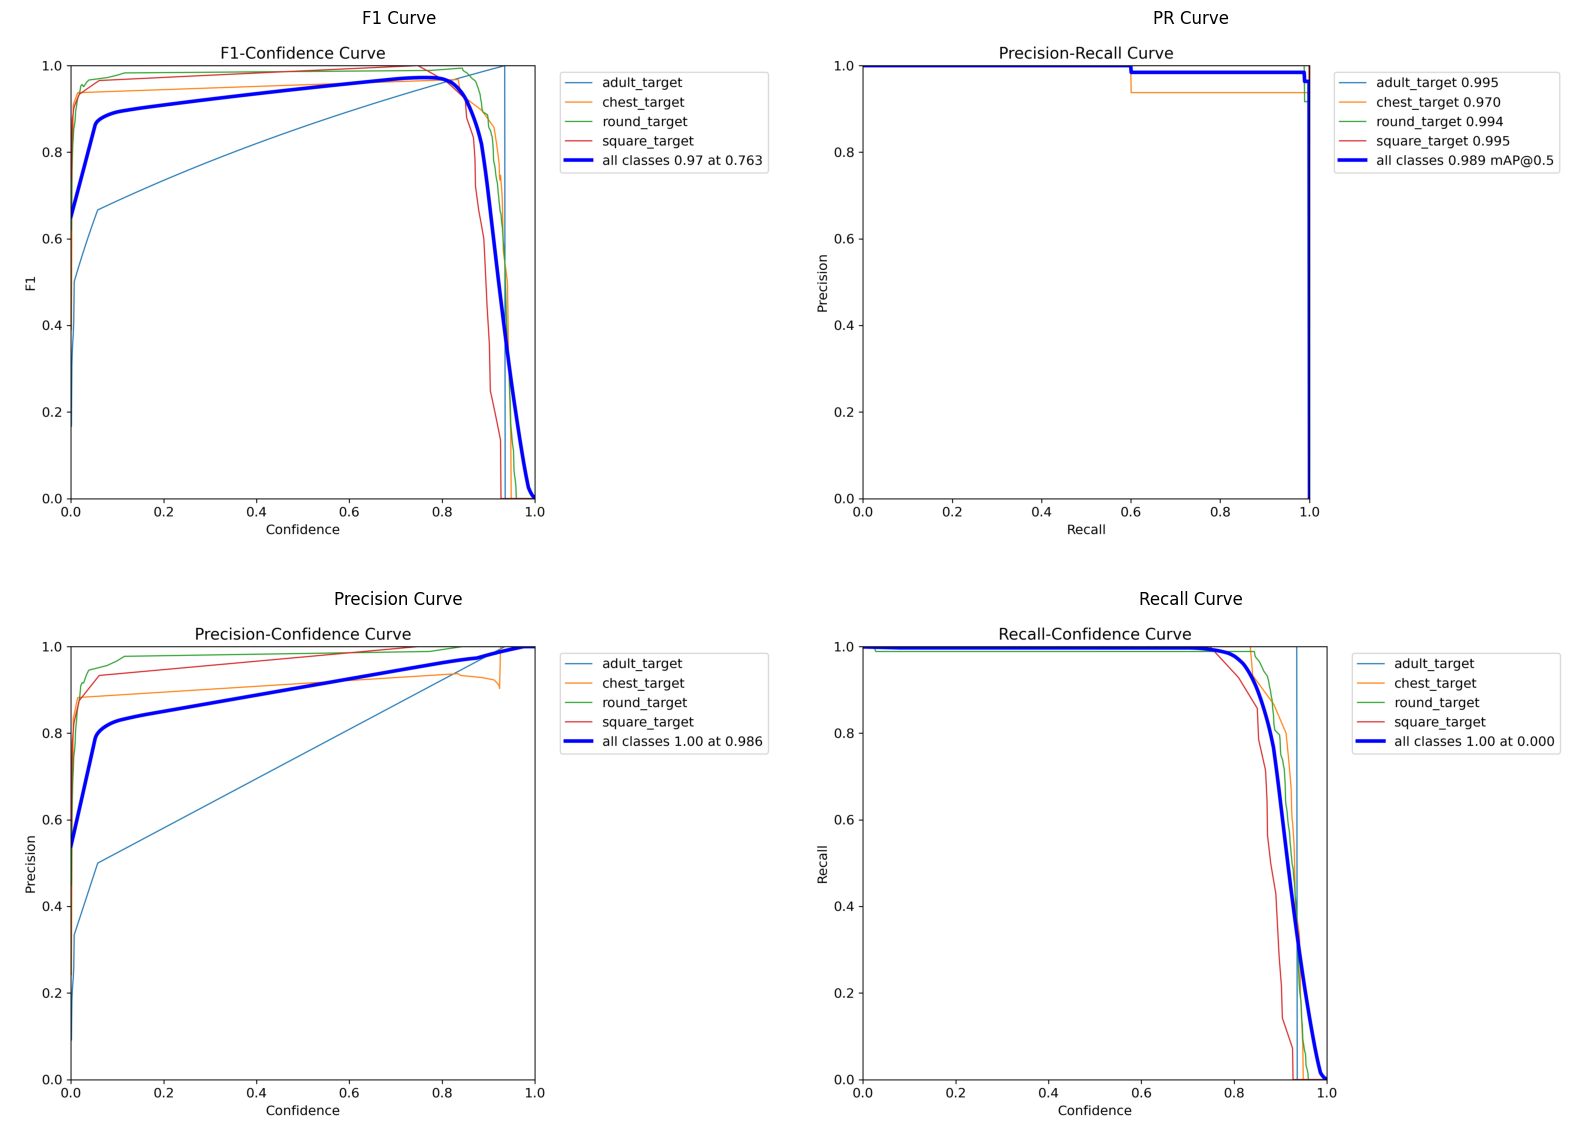

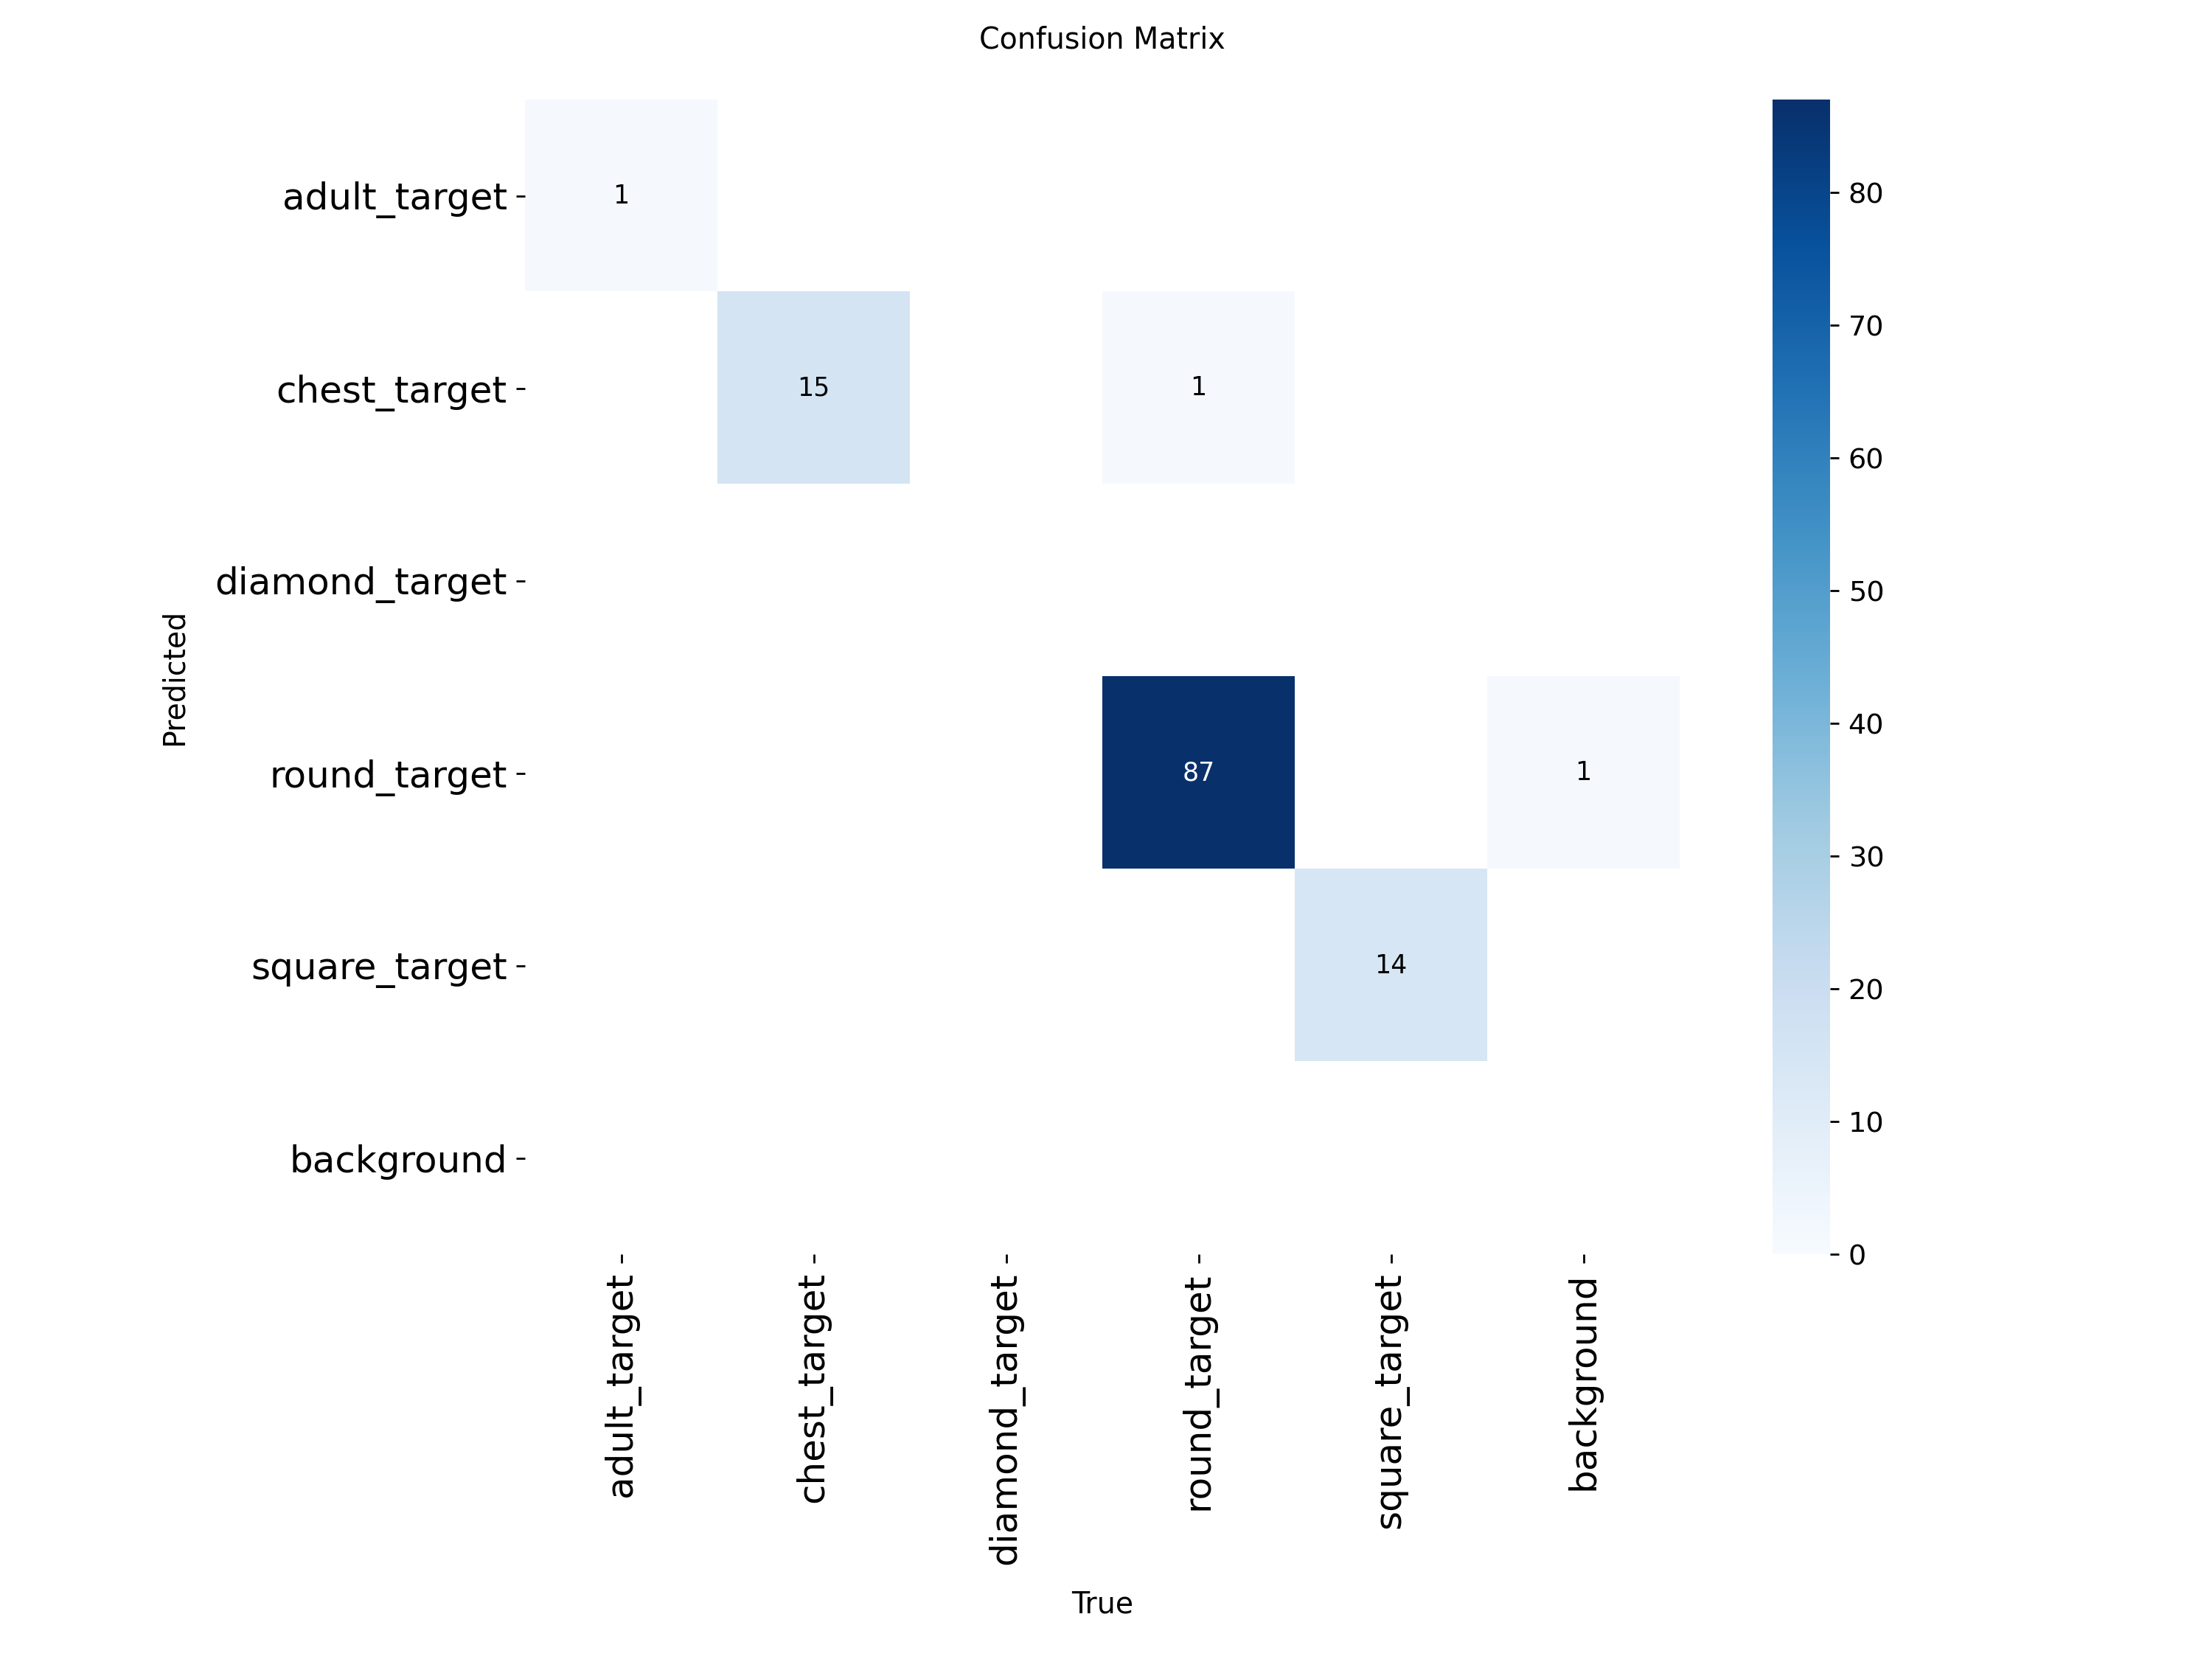

In [7]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# 1. Cargar el modelo
model = YOLO(f'{entrenamiento_dir}/weights/best.pt')

# 2. Evaluar sobre TEST (fijamos el nombre de la carpeta a 'test_results')
print("Ejecutando evaluación sobre el conjunto de Test...")
metrics = model.val(data=str(dataset_yaml), split="test", plots=True, workers=0,
                    project=str(run_dir), name="test_results", exist_ok=True)

# 3. Ruta fija de resultados de test
test_dir = metrics.save_dir

# 4. Mostrar las métricas gráficas con los nombres específicos detectados
print("\n--- 3. Métricas de Rendimiento sobre Test ---")

# Configurar el lienzo (2 filas, 2 columnas)
fig, axs = plt.subplots(2, 2, figsize=(16, 12))

# Cargar y mostrar cada imagen en su posición específica
axs[0, 0].imshow(mpimg.imread(f'{test_dir}/BoxF1_curve.png'))
axs[0, 0].set_title('F1 Curve')
axs[0, 0].axis('off')

axs[0, 1].imshow(mpimg.imread(f'{test_dir}/BoxPR_curve.png'))
axs[0, 1].set_title('PR Curve')
axs[0, 1].axis('off')

axs[1, 0].imshow(mpimg.imread(f'{test_dir}/BoxP_curve.png'))
axs[1, 0].set_title('Precision Curve')
axs[1, 0].axis('off')

axs[1, 1].imshow(mpimg.imread(f'{test_dir}/BoxR_curve.png'))
axs[1, 1].set_title('Recall Curve')
axs[1, 1].axis('off')

plt.tight_layout()
plt.show()
display(Image(filename=f'{test_dir}/confusion_matrix.png'))

## Prueba Visual (1 Imagen Aleatoria del Test)
El sigueinte codigo coge una imagen del test y la muestra con las detecciones del modelo.

In [ ]:
import random
import cv2
import matplotlib.pyplot as plt
import glob

# Obtener imágenes de test
test_images = sorted((dataset_dir / "test" / "images").glob("*.jpg"))
imagen_azar = str(random.choice(test_images))

# Predecir y graficar
print("--- 4. Prueba Visual: Detección Real ---")
results = model.predict(imagen_azar, conf=0.5)
res_plotted = results[0].plot()
res_rgb = cv2.cvtColor(res_plotted, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(res_rgb)
plt.axis('off')
plt.title(f"Detección sobre imagen de test: {os.path.basename(imagen_azar)}")
plt.show()

# 4. Conclusiones
Al dotar de "ojos" a la torreta hemos demostrado que usar Transfer Learning con una red moderna como YOLOv8 es una estrategia mucho más eficiente que intentar entrenar una CNN desde cero, permitiéndonos obtener una precisión muy buena con muy pocos datos.

Además si quisieramos que la torreta disparase a otras cosas, podriamos generar otro modelo con otro dataset, lo que ofrece mucha versatilidad.

Referencias y Fuentes
- Librería Principal: Ultralytics YOLOv8 Docs (https://docs.ultralytics.com/)
- Tutorial Base: Object Detection using YOLOv8 - GeeksforGeeks (https://www.geeksforgeeks.org/machine-learning/object-detection-using-yolov8/)
- Dataset: Shooting Target Object Detection - Roboflow Universe (https://universe.roboflow.com/final-project-lmkzv/shooting-target)
- Apuntes de la asignatura (Tema 5: CNNs) y explicacion sobre como funciona YOLOv8 (https://es.wikipedia.org/wiki/Algoritmo_You_Only_Look_Once_(YOLO))